In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import pennylane as qml
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_class_weight
from imblearn.combine import SMOTETomek

In [8]:
df = pd.read_csv('IoT_Network_Intrusion_Dataset.csv', delimiter=',', encoding='utf-8')
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 625783 entries, 0 to 625782
Data columns (total 86 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Flow_ID            625783 non-null  object 
 1   Src_IP             625783 non-null  object 
 2   Src_Port           625783 non-null  int64  
 3   Dst_IP             625783 non-null  object 
 4   Dst_Port           625783 non-null  int64  
 5   Protocol           625783 non-null  int64  
 6   Timestamp          625783 non-null  object 
 7   Flow_Duration      625783 non-null  int64  
 8   Tot_Fwd_Pkts       625783 non-null  int64  
 9   Tot_Bwd_Pkts       625783 non-null  int64  
 10  TotLen_Fwd_Pkts    625783 non-null  float64
 11  TotLen_Bwd_Pkts    625783 non-null  float64
 12  Fwd_Pkt_Len_Max    625783 non-null  float64
 13  Fwd_Pkt_Len_Min    625783 non-null  float64
 14  Fwd_Pkt_Len_Mean   625783 non-null  float64
 15  Fwd_Pkt_Len_Std    625783 non-null  float64
 16  Bw

In [ ]:
# DATA PREPROCESSING


columns_to_drop = ['Flow_ID', 'Src_IP', 'Dst_IP', 'Timestamp', 'Cat', 'Sub_Cat']
df.drop(columns=columns_to_drop, inplace=True, errors='ignore')

# replacing invalid values  with nan
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# replacing nans with the means of each column
df.fillna(df.mean(numeric_only=True), inplace=True)


print(df['Label'].unique())

# removing whitespaces from labels
# df['Label'] = df['Label'].str.strip()

# label encoding ('Anomaly' -> 0, 'Normal' -> 1)
le = LabelEncoder()
df['Label'] = le.fit_transform(df['Label'])

print("Encoded labels mapping:")
for idx, label in enumerate(le.classes_):
    print(f"{label} -> {idx}")
    

X = df.drop('Label', axis=1)
y = df['Label']


X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    test_size=0.2, 
                                                    random_state=42)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


X_train_small, y_train_small = X_train_scaled[:200, :4], y_train[:200]
X_test_small, y_test_small   = X_test_scaled[:100, :4], y_test[:100]

# applying SMOTE to balance the training dataset

smote_tomek = SMOTETomek(random_state=42)
X_train_balanced, y_train_balanced = smote_tomek.fit_resample(X_train_small, 
                                                              y_train_small)
print(f"Original class distribution: {np.bincount(y_train_small)}")
print(f"Balanced class distribution: {np.bincount(y_train_balanced)}")


['Anomaly' 'Normal']
Encoded labels mapping:
Anomaly -> 0
Normal -> 1
Original class distribution: [188  12]
Balanced class distribution: [188 188]


In [6]:
X_train_small, y_train_small = X_train_scaled[:200, :4], y_train[:200]
X_test_small, y_test_small   = X_test_scaled[:100, :4], y_test[:100]
# df.info()

In [10]:
# dev = qml.device("lightning.gpu", wires=4)
# define a quantum device (simulator)
dev = qml.device("lightning.qubit", wires=4)

@qml.qnode(dev)
def kernel_circuit(x1, x2):
    qml.AngleEmbedding(x1, wires=range(4))
    for wire in range(4):
        qml.Hadamard(wires=wire)
    qml.AngleEmbedding(x2, wires=range(4))
    return qml.probs(wires=range(4))

def compute_kernel_matrix(X1, X2):
    """Compute the kernel matrix between two datasets."""
    n_samples_1, n_samples_2 = len(X1), len(X2)
    kernel_matrix = np.zeros((n_samples_1, n_samples_2))

    print(f"Computing kernel matrix of size {n_samples_1}x{n_samples_2}...")
    
    for i in range(n_samples_1):
        if i % 10 == 0:
            print(f"Computing row {i+1}/{n_samples_1}...")
        for j in range(n_samples_2):
            kernel_matrix[i, j] = kernel_circuit(X1[i], X2[j])[0]

    print("Kernel matrix computation completed.")
    return kernel_matrix

Starting training kernel matrix computation...
Computing kernel matrix of size 376x376...
Computing row 1/376...
Computing row 11/376...
Computing row 21/376...
Computing row 31/376...
Computing row 41/376...
Computing row 51/376...
Computing row 61/376...
Computing row 71/376...
Computing row 81/376...
Computing row 91/376...
Computing row 101/376...
Computing row 111/376...
Computing row 121/376...
Computing row 131/376...
Computing row 141/376...
Computing row 151/376...
Computing row 161/376...
Computing row 171/376...
Computing row 181/376...
Computing row 191/376...
Computing row 201/376...
Computing row 211/376...
Computing row 221/376...
Computing row 231/376...
Computing row 241/376...
Computing row 251/376...
Computing row 261/376...
Computing row 271/376...
Computing row 281/376...
Computing row 291/376...
Computing row 301/376...
Computing row 311/376...
Computing row 321/376...
Computing row 331/376...
Computing row 341/376...
Computing row 351/376...
Computing row 361/376

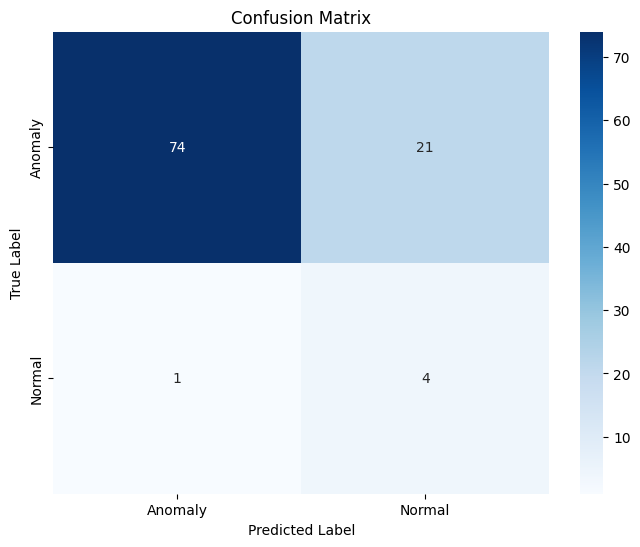

In [ ]:
print("Starting training kernel matrix computation...")
training_kernel_matrix = compute_kernel_matrix(X_train_balanced, X_train_balanced)

print("Starting testing kernel matrix computation...")
testing_kernel_matrix = compute_kernel_matrix(X_test_small, X_train_balanced)


from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

print("Training classical SVM with quantum kernel...")

# class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train_balanced), y=y_train_balanced)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}

# grid search to get best C value
param_grid = {'C': [0.00001, 0.0001, 0.001, 0.01, 0.1, 1]}
svm_model = SVC(kernel="precomputed", class_weight=class_weights_dict)

grid_search = GridSearchCV(estimator=svm_model,
                           param_grid=param_grid,
                           scoring='f1_weighted',  # use F1-score for imbalanced datasets
                           cv=5,
                           verbose=1)

grid_search.fit(training_kernel_matrix, y_train_balanced)

# training the model using best C value from grid search
best_C = grid_search.best_params_['C']
svm_model_best = SVC(kernel="precomputed", C=best_C, class_weight=class_weights_dict)
svm_model_best.fit(training_kernel_matrix, y_train_balanced)

# predictions
y_pred_qsvc = svm_model_best.predict(testing_kernel_matrix)

# evaluation metrics
accuracy_qsvc = accuracy_score(y_test_small, y_pred_qsvc)
print(f"QSVM Accuracy on Test Data: {accuracy_qsvc:.4f}")

print("Classification Report:")
print(classification_report(y_test_small, y_pred_qsvc))

cm = confusion_matrix(y_test_small, y_pred_qsvc)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Anomaly", "Normal"], yticklabels=["Anomaly", "Normal"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

Computing kernel matrix of size 1298x1298...
Computing row 1/1298...
Computing row 11/1298...
Computing row 21/1298...
Computing row 31/1298...
Computing row 41/1298...
Computing row 51/1298...
Computing row 61/1298...
Computing row 71/1298...
Computing row 81/1298...
Computing row 91/1298...
Computing row 101/1298...
Computing row 111/1298...
Computing row 121/1298...
Computing row 131/1298...
Computing row 141/1298...
Computing row 151/1298...
Computing row 161/1298...
Computing row 171/1298...
Computing row 181/1298...
Computing row 191/1298...
Computing row 201/1298...
Computing row 211/1298...
Computing row 221/1298...
Computing row 231/1298...
Computing row 241/1298...
Computing row 251/1298...
Computing row 261/1298...
Computing row 271/1298...
Computing row 281/1298...
Computing row 291/1298...
Computing row 301/1298...
Computing row 311/1298...
Computing row 321/1298...
Computing row 331/1298...
Computing row 341/1298...
Computing row 351/1298...
Computing row 361/1298...
Comp

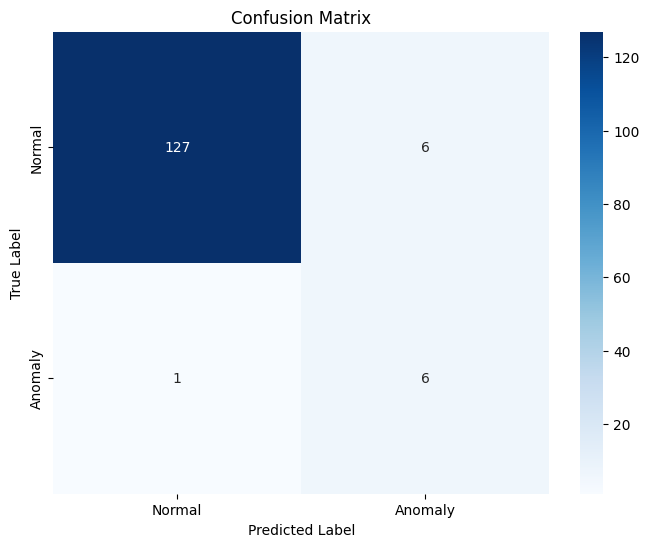

In [12]:
# Compute class weights for cost-sensitive learning
class_weights = compute_class_weight('balanced', classes=np.unique(y_train_balanced), y=y_train_balanced)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}

# Compute kernel matrices
training_kernel_matrix = compute_kernel_matrix(X_train_balanced, X_train_balanced)
testing_kernel_matrix = compute_kernel_matrix(X_test_small, X_train_balanced)

# Perform grid search with an expanded range of C values
param_grid = {'C': [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}
svm_model = SVC(kernel="precomputed", class_weight=class_weights_dict)

grid_search = GridSearchCV(estimator=svm_model,
                           param_grid=param_grid,
                           scoring='f1_weighted',  # Use F1-score for imbalanced datasets
                           cv=5,
                           verbose=1)

grid_search.fit(training_kernel_matrix, y_train_balanced)

# Train the best model on the full balanced training set using best C value from GridSearchCV
best_C = grid_search.best_params_['C']
svm_model_best = SVC(kernel="precomputed", C=best_C, class_weight=class_weights_dict)
svm_model_best.fit(training_kernel_matrix, y_train_balanced)

# Make predictions on test data
y_pred_qsvc = svm_model_best.predict(testing_kernel_matrix)

# Evaluate results
accuracy_qsvc = accuracy_score(y_test_small, y_pred_qsvc)
print(f"QSVM Accuracy on Test Data: {accuracy_qsvc:.4f}")

print("Classification Report:")
print(classification_report(y_test_small, y_pred_qsvc))

cm = confusion_matrix(y_test_small, y_pred_qsvc)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

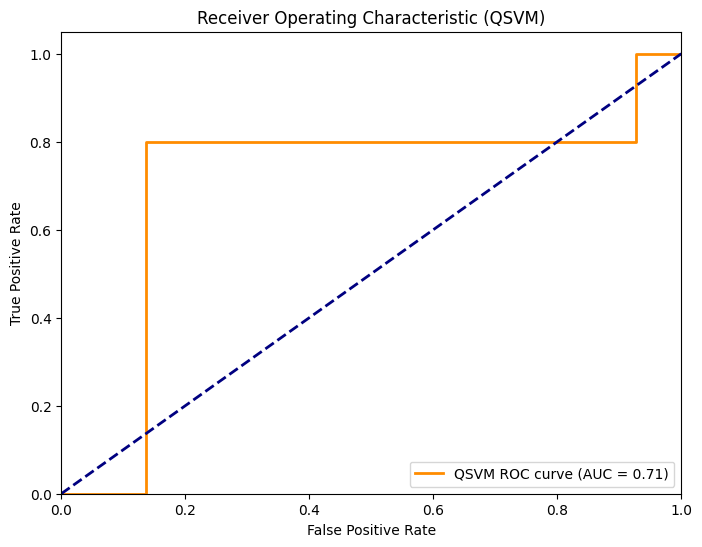

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# decision scores for ROC curve
y_score_qsvc = svm_model_best.decision_function(testing_kernel_matrix)

# calculate ROC curve and AUC
fpr_qsvc, tpr_qsvc, _ = roc_curve(y_test_small, y_score_qsvc)
roc_auc_qsvc = auc(fpr_qsvc, tpr_qsvc)


plt.figure(figsize=(8, 6))
plt.plot(fpr_qsvc, tpr_qsvc, color='darkorange', lw=2,
         label=f'QSVM ROC curve (AUC = {roc_auc_qsvc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (QSVM)')
plt.legend(loc="lower right")
plt.show()


In [ ]:
print("Starting training kernel matrix computation...")
training_kernel_matrix = compute_kernel_matrix(X_train_small, X_train_small)

print("Starting testing kernel matrix computation...")
testing_kernel_matrix = compute_kernel_matrix(X_test_small, X_train_small)


from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

print("Training classical SVM with quantum kernel...")



param_grid = {'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}
# svm_model = SVC(kernel="precomputed")
# performing grid search w/ cross-validation
# grid_search = GridSearchCV(estimator=svm_model,
#                            param_grid=param_grid,
#                            scoring='accuracy',
#                            cv=5,
#                            verbose=1)


# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train_small), y=y_train_small)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}

# Update SVM with class weights
svm_model = SVC(kernel="precomputed", class_weight=class_weights_dict)

# Perform grid search with cross-validation
grid_search = GridSearchCV(estimator=svm_model,
                           param_grid=param_grid,
                           scoring='accuracy',
                           cv=5,
                           verbose=1)

# fit the model using the training_kernel_matrix
grid_search.fit(training_kernel_matrix, y_train_small)


print("Best C:", grid_search.best_params_['C'])
print("Best Accuracy:", grid_search.best_score_)

In [ ]:
# Training the model on the full training set using best c value from gridSearchCV
best_C = grid_search.best_params_['C']
svm_model_best = SVC(kernel="precomputed", C=best_C)
svm_model_best.fit(training_kernel_matrix, y_train_small)

print("Making predictions on test data...")
y_pred_qsvc = svm_model_best.predict(testing_kernel_matrix)

# accuracy
accuracy_qsvc = accuracy_score(y_test_small, y_pred_qsvc)
print(f"QSVM Accuracy on Test Data: {accuracy_qsvc:.4f}")

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test_small, y_pred_qsvc)

# plot cm
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Anomaly", "Normal"], yticklabels=["Anomaly", "Normal"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# classification report
print("Classification Report:")
print(classification_report(y_test_small, y_pred_qsvc))

# precision, Recall, F1-Score
precision = precision_score(y_test_small, y_pred_qsvc, average='weighted')
recall = recall_score(y_test_small, y_pred_qsvc, average='weighted')
f1 = f1_score(y_test_small, y_pred_qsvc, average='weighted')

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

In [8]:
# number of samples classified as anomaly (0) and normal (1)
anomaly_count = np.sum(y_pred_qsvc == 0)
normal_count = np.sum(y_pred_qsvc == 1)

print(f"Number of samples classified as Anomaly: {anomaly_count}")
print(f"Number of samples classified as Normal: {normal_count}")

Number of samples classified as Anomaly: 107
Number of samples classified as Normal: 33


In [ ]:
# Load the original dataset to retrieve 'Cat' column
file_path = 'IoT_Network_Intrusion_Dataset.csv'
df_original = pd.read_csv(file_path, delimiter=',', encoding='utf-8')

# Extract the 'Cat' column for the test set
categories_test = df_original.loc[df_original.index[:len(y_test_small)], 'Cat']

# Create a DataFrame to store predictions and actual categories
results_df = pd.DataFrame({'Actual': categories_test, 'Predicted': y_pred_qsvc})

# Calculate detection percentages for each attack type
attack_types = results_df['Actual'].unique()
detection_percentages = {}

for attack in attack_types:
    actual_count = results_df[results_df['Actual'] == attack].shape[0]
    detected_count = results_df[(results_df['Actual'] == attack) & (results_df['Predicted'] == 0)].shape[0]
    detection_percentages[attack] = (detected_count / actual_count) * 100 if actual_count > 0 else 0

# Print detection percentages for each attack type
print("Detection Percentages for Each Attack Type:")
for attack, percentage in detection_percentages.items():
    print(f"{attack}: {percentage:.2f}%")

# Calculate percentage of normal samples detected
normal_total_count = np.sum(results_df['Actual'] == 'Normal')
normal_detected_count = np.sum((results_df['Actual'] == 'Normal') & (results_df['Predicted'] == 1))
normal_detection_percentage = (normal_detected_count / normal_total_count) * 100 if normal_total_count > 0 else 0

print(f"Percentage of Normal Samples Detected: {normal_detection_percentage:.2f}%")
